# Lab-5(ML)

## Name-Aayush Kulkarni
## Class-B-B4-53

 Github Link-https://github.com/kulkarniaayush90-sys/Machine-Learning-Lab-5.git

## Aim
To implement the K-Nearest Neighbors (KNN) algorithm for both classification and regression using suitable datasets.

## Objectives
- Understand the working principle of the K-Nearest Neighbors algorithm.
- Apply KNN classification and evaluate its performance.
- Apply KNN regression and evaluate prediction errors.
- Perform exploratory data analysis (EDA) before model training.
- Compare actual and predicted values using metrics and visualizations.

## Theory
K-Nearest Neighbors is a supervised, instance-based learning algorithm. It predicts an observation using the labels or values of its nearest training samples. The distance between samples is commonly measured using Euclidean distance. For classification, the most frequent class among the K nearest neighbors is selected. For regression, the average target value of the K nearest neighbors is used.

Feature scaling is important for KNN because distance calculations can be dominated by features with larger numerical ranges. The parameter `n_neighbors` determines the number of neighbors considered. A small K can be sensitive to noise, while a large K can smooth decision boundaries and may underfit.

**Classification metrics:** accuracy, precision, recall, F1-score, and confusion matrix.

**Regression metrics:** mean absolute error (MAE), mean squared error (MSE), root mean squared error (RMSE), and coefficient of determination (R²).

## Datasets / Resources Used
- **Classification:** User-provided Pima Indians Diabetes CSV (`diabetes (6) - diabetes (6).csv`), using `Outcome` as the target.
- **Regression:** Diabetes disease-progression dataset available through `sklearn.datasets`.
- Python libraries: pandas, NumPy, Matplotlib, Seaborn, and scikit-learn.

Keep the supplied CSV in the same folder as the notebook, or upload it when prompted in Google Colab.

## Procedure
1. Import the required Python libraries.
2. Load the supplied Pima Indians Diabetes CSV for classification.
3. Perform EDA before training: inspect data types, missing values, duplicates, summary statistics, outcome distribution, histograms, boxplots, a correlation heatmap, and a scatter plot.
4. Inspect zero values in medical measurement columns and handle them as potentially missing during preprocessing.
5. Split the classification data into training and testing sets, impute missing feature values, standardize features, and train a KNN classifier.
6. Evaluate classification using accuracy, precision, recall, F1-score, classification report, and confusion matrix.
7. Load the scikit-learn Diabetes dataset for regression and perform EDA before modeling.
8. Split the regression data, standardize features, train a KNN regressor, and evaluate regression metrics.
9. Plot actual versus predicted regression values and summarize the results.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris, load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix,
    mean_absolute_error, mean_squared_error, r2_score
)

sns.set_theme(style="whitegrid")

## Part A: KNN Classification — Pima Indians Diabetes Dataset

This experiment uses the user-provided CSV file `diabetes (6) - diabetes (6).csv`. The target column is `Outcome` (0 = non-diabetic, 1 = diabetic). Place the CSV in the same folder as this notebook, or upload it to the current Colab session before running the data-loading cell.

In [2]:
df_class = pd.read_csv("diabetes (6) - diabetes (6).csv")

print("Dataset shape:", df_class.shape)
display(df_class.head())

Dataset shape: (768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


### EDA — Classification Dataset

In [3]:
# Inspect structure, data types, missing values, duplicates, and summary statistics
print("Dataset information:")
df_class.info()

print("\nMissing values:")
display(df_class.isnull().sum().to_frame("Missing Values"))

print("\nDuplicate rows:", df_class.duplicated().sum())

print("\nDescriptive statistics:")
display(df_class.describe().T)

print("\nOutcome counts:")
display(df_class["Outcome"].value_counts().sort_index().rename(index={0: "No diabetes", 1: "Diabetes"}).to_frame("Count"))

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB

Missing values:


,Missing Values
Pregnancies,0
Glucose,0
BloodPressure,0
SkinThickness,0
Insulin,0
BMI,0
DiabetesPedigreeFunction,0
Age,0
Outcome,0



Duplicate rows: 0

Descriptive statistics:


,count,mean,std,min,25%,50%,75%,max
Pregnancies,768.0,3.845052,3.369578,0.000,1.00000,3.0000,6.00000,17.00
Glucose,768.0,120.894531,31.972618,0.000,99.00000,117.0000,140.25000,199.00
BloodPressure,768.0,69.105469,19.355807,0.000,62.00000,72.0000,80.00000,122.00
SkinThickness,768.0,20.536458,15.952218,0.000,0.00000,23.0000,32.00000,99.00
Insulin,768.0,79.799479,115.244002,0.000,0.00000,30.5000,127.25000,846.00
BMI,768.0,31.992578,7.884160,0.000,27.30000,32.0000,36.60000,67.10
DiabetesPedigreeFunction,768.0,0.471876,0.331329,0.078,0.24375,0.3725,0.62625,2.42
Age,768.0,33.240885,11.760232,21.000,24.00000,29.0000,41.00000,81.00
Outcome,768.0,0.348958,0.476951,0.000,0.00000,0.0000,1.00000,1.00



Outcome counts:


,Count
Outcome,
No diabetes,500
Diabetes,268


In [4]:
# Check zero values in medical measurements.
# In this dataset, zero values for Glucose, BloodPressure, SkinThickness, Insulin, and BMI
# may represent missing measurements rather than genuine measurements.
measurement_cols = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
zero_counts = (df_class[measurement_cols] == 0).sum().to_frame("Zero Values")
display(zero_counts)

,Zero Values
Glucose,5
BloodPressure,35
SkinThickness,227
Insulin,374
BMI,11


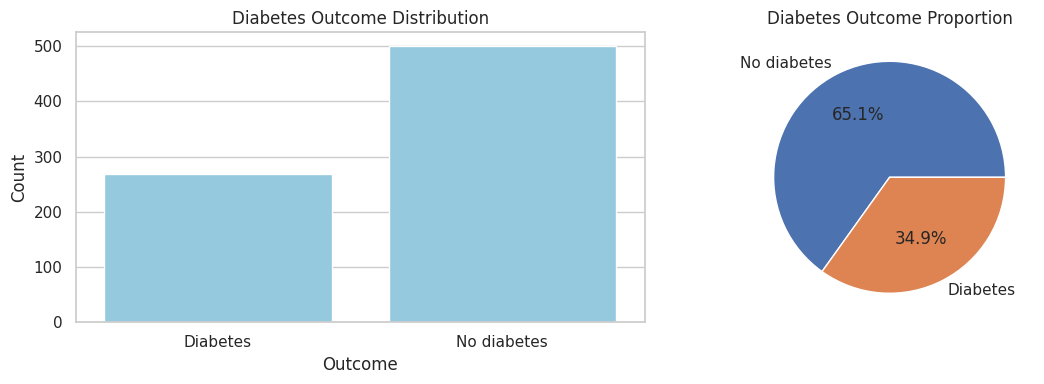

In [5]:
# Outcome distribution: bar chart and pie chart
outcome_labels = df_class["Outcome"].map({0: "No diabetes", 1: "Diabetes"})
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(x=outcome_labels, ax=axes[0], color="skyblue")
axes[0].set_title("Diabetes Outcome Distribution")
axes[0].set_xlabel("Outcome")
axes[0].set_ylabel("Count")
outcome_labels.value_counts().plot(kind="pie", autopct="%1.1f%%", ax=axes[1])
axes[1].set_title("Diabetes Outcome Proportion")
axes[1].set_ylabel("")
plt.tight_layout()
plt.show()

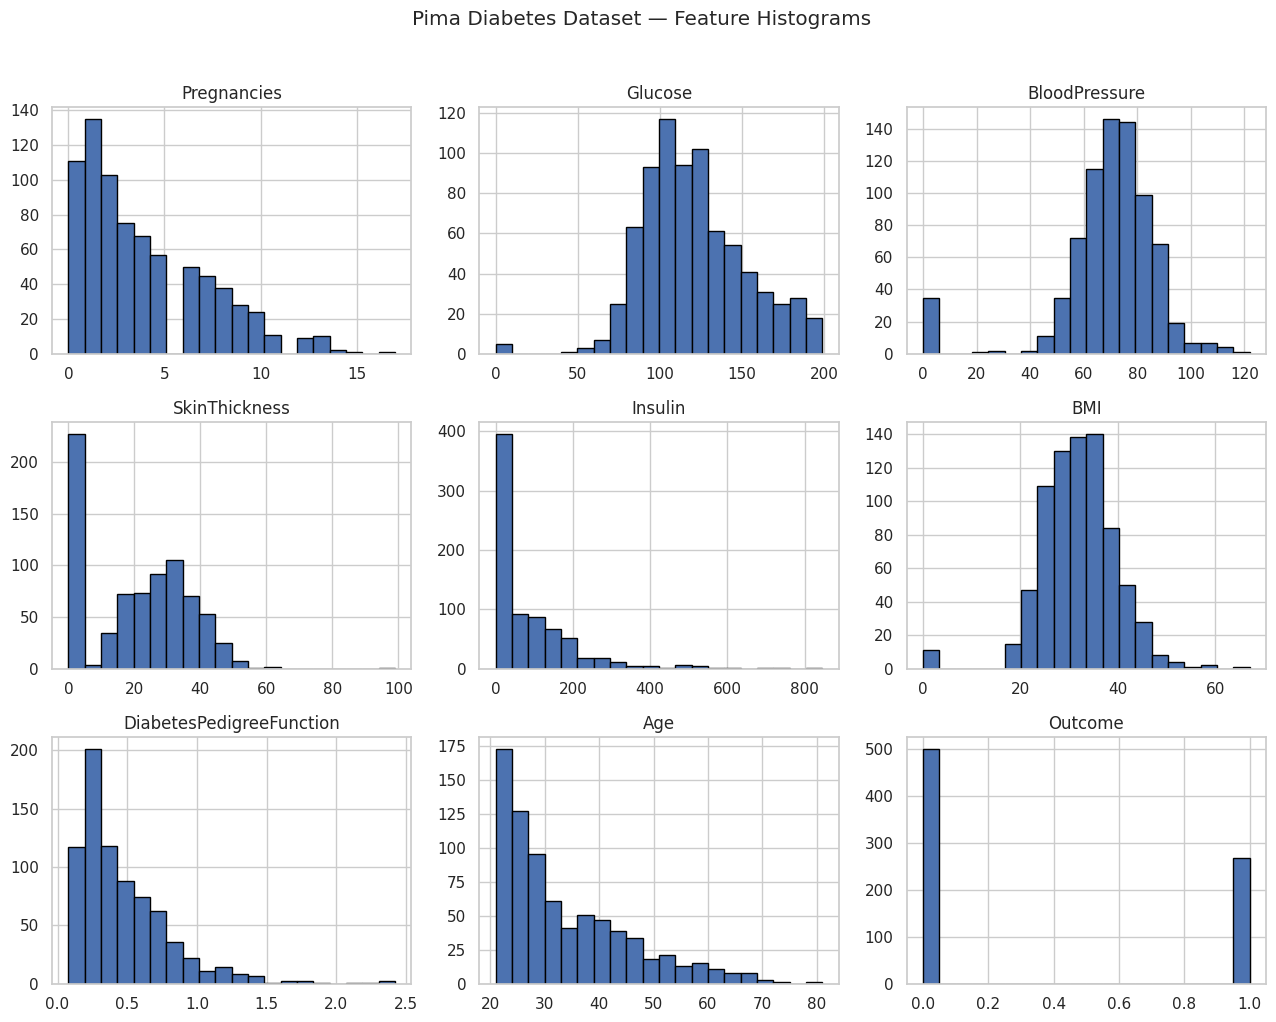

In [6]:
# Histograms for numeric features
df_class.hist(figsize=(13, 10), bins=20, edgecolor="black")
plt.suptitle("Pima Diabetes Dataset — Feature Histograms", y=1.02)
plt.tight_layout()
plt.show()

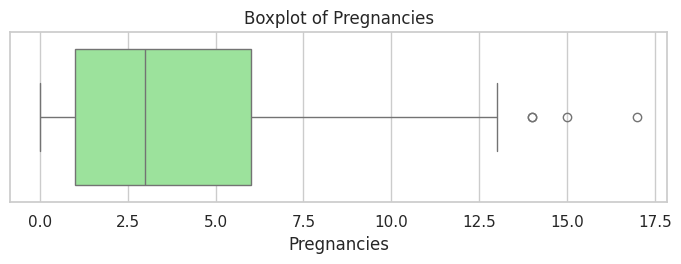

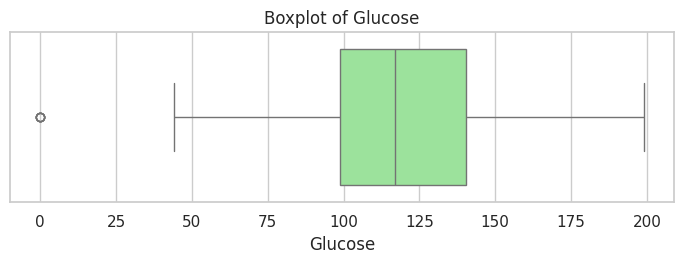

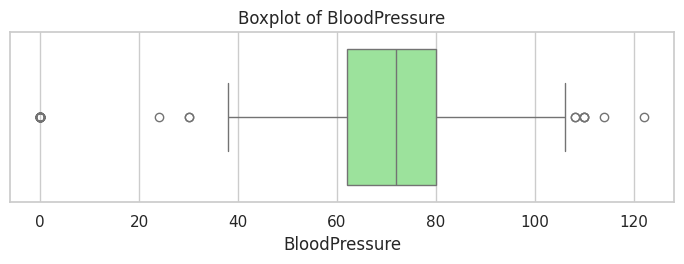

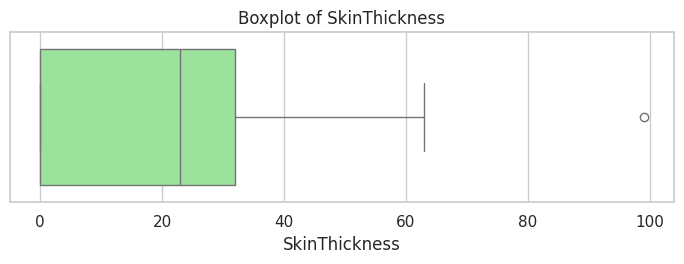

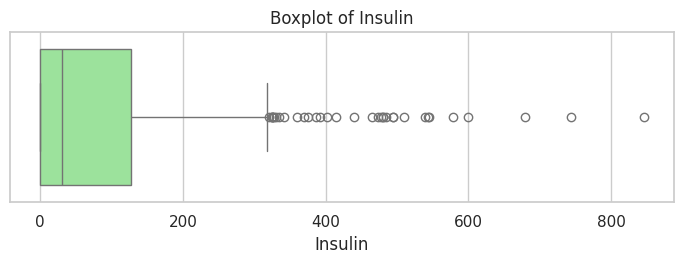

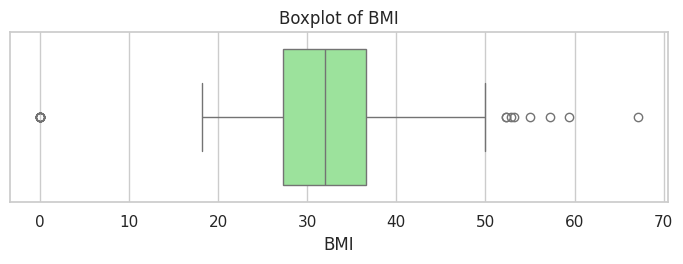

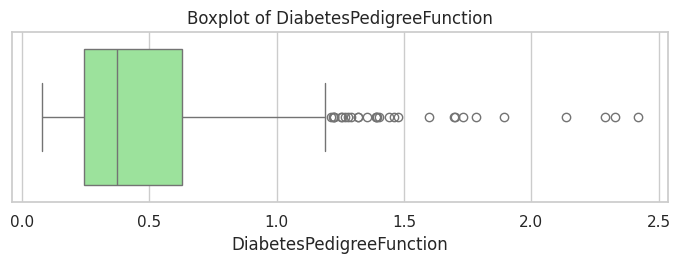

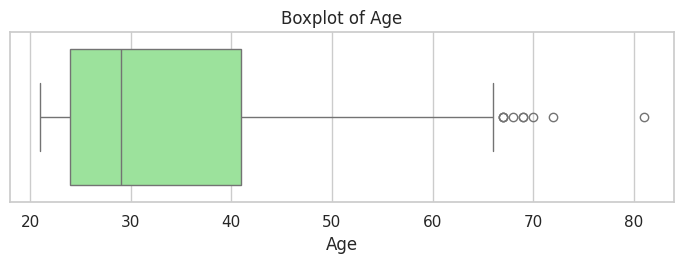

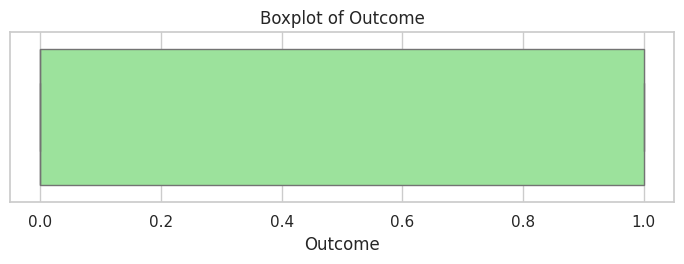

In [7]:
# Boxplots for numeric features to inspect distributions and potential outliers
for col in df_class.columns:
    plt.figure(figsize=(7, 2.8))
    sns.boxplot(x=df_class[col], color="lightgreen")
    plt.title(f"Boxplot of {col}")
    plt.tight_layout()
    plt.show()

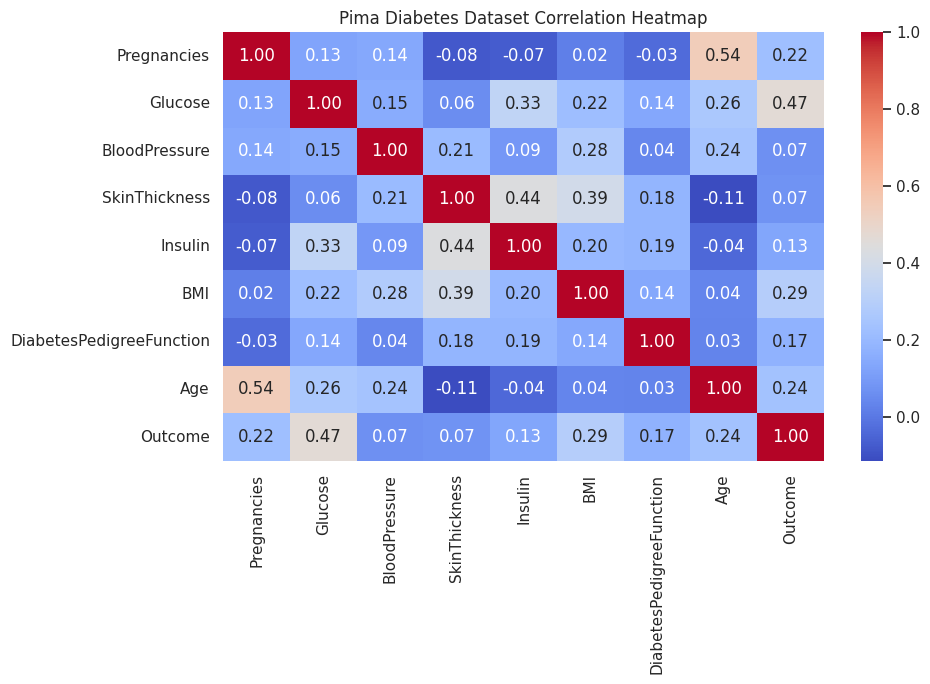

In [8]:
# Correlation heatmap
plt.figure(figsize=(10, 7))
sns.heatmap(df_class.corr(numeric_only=True), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Pima Diabetes Dataset Correlation Heatmap")
plt.tight_layout()
plt.show()

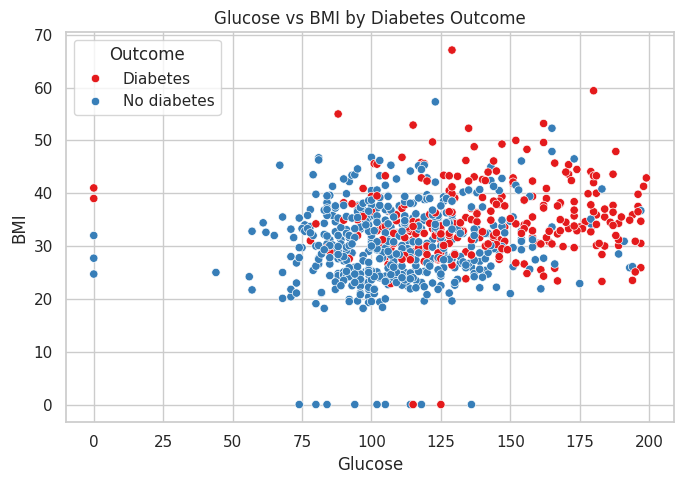

In [9]:
# Scatter plot: Glucose versus BMI, colored by diabetes outcome
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df_class, x="Glucose", y="BMI", hue=outcome_labels, palette="Set1")
plt.title("Glucose vs BMI by Diabetes Outcome")
plt.tight_layout()
plt.show()

### Preprocessing and Train-Test Split

Zero values in selected medical measurement columns are treated as potentially missing. The median imputer learns replacement values from the training data only. Features are standardized because KNN uses distance calculations. The target `Outcome` is not imputed or scaled.

In [10]:
from sklearn.impute import SimpleImputer
from sklearn.metrics import ConfusionMatrixDisplay

X_class = df_class.drop(columns=["Outcome"])
y_class = df_class["Outcome"]

X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    X_class, y_class, test_size=0.2, random_state=42, stratify=y_class
)

# Treat zero values in these columns as missing for preprocessing
X_train_c = X_train_c.copy()
X_test_c = X_test_c.copy()
zero_as_missing_cols = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
X_train_c[zero_as_missing_cols] = X_train_c[zero_as_missing_cols].replace(0, np.nan)
X_test_c[zero_as_missing_cols] = X_test_c[zero_as_missing_cols].replace(0, np.nan)

print("Training features:", X_train_c.shape)
print("Testing features:", X_test_c.shape)

Training features: (614, 8)
Testing features: (154, 8)


In [11]:
# Impute missing measurements, standardize features, then train the KNN classifier
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

knn_classifier = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier(n_neighbors=5))
])

knn_classifier.fit(X_train_c, y_train_c)
y_pred_c = knn_classifier.predict(X_test_c)

In [12]:
print("Classification Accuracy:", round(accuracy_score(y_test_c, y_pred_c), 4))
print("Weighted Precision:", round(precision_score(y_test_c, y_pred_c, average="weighted", zero_division=0), 4))
print("Weighted Recall:", round(recall_score(y_test_c, y_pred_c, average="weighted", zero_division=0), 4))
print("Weighted F1-score:", round(f1_score(y_test_c, y_pred_c, average="weighted", zero_division=0), 4))
print("\nClassification Report:")
print(classification_report(y_test_c, y_pred_c, target_names=["No diabetes", "Diabetes"], zero_division=0))

Classification Accuracy: 0.7532
Weighted Precision: 0.7497
Weighted Recall: 0.7532
Weighted F1-score: 0.7509

Classification Report:
              precision    recall  f1-score   support

 No diabetes       0.80      0.83      0.81       100
    Diabetes       0.66      0.61      0.63        54

    accuracy                           0.75       154
   macro avg       0.73      0.72      0.72       154
weighted avg       0.75      0.75      0.75       154



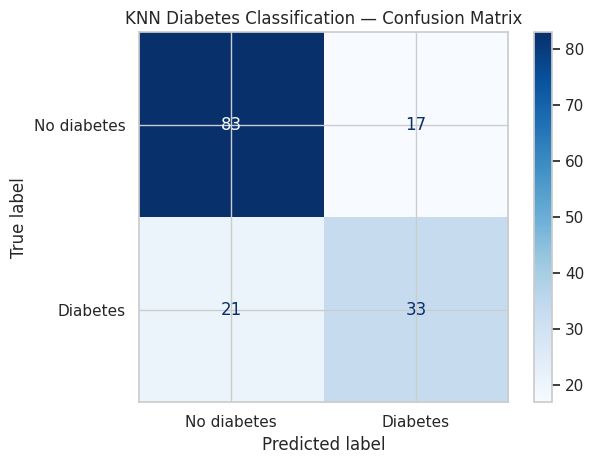

In [13]:
# Confusion matrix
cm = confusion_matrix(y_test_c, y_pred_c, labels=[0, 1])
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["No diabetes", "Diabetes"])
disp.plot(cmap="Blues", values_format="d")
plt.title("KNN Diabetes Classification — Confusion Matrix")
plt.tight_layout()
plt.show()

In [14]:
# Compare actual and predicted outcomes
classification_comparison = pd.DataFrame({
    "Actual Outcome": y_test_c.reset_index(drop=True).map({0: "No diabetes", 1: "Diabetes"}),
    "Predicted Outcome": pd.Series(y_pred_c).map({0: "No diabetes", 1: "Diabetes"})
})
display(classification_comparison.head(10))

,Actual Outcome,Predicted Outcome
0,No diabetes,Diabetes
1,No diabetes,No diabetes
2,No diabetes,No diabetes
3,Diabetes,Diabetes
4,No diabetes,No diabetes
5,No diabetes,No diabetes
6,Diabetes,No diabetes
7,Diabetes,Diabetes
8,No diabetes,No diabetes
9,No diabetes,Diabetes


## Part B: KNN Regression

In [15]:
# Load the Diabetes dataset
diabetes = load_diabetes(as_frame=True)
df_reg = diabetes.frame.copy()

print("Dataset shape:", df_reg.shape)
display(df_reg.head())

Dataset shape: (442, 11)


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


### EDA — Regression Dataset

In [16]:
print("Dataset information:")
df_reg.info()

print("\nMissing values:")
display(df_reg.isnull().sum().to_frame("Missing Values"))

print("\nDescriptive statistics:")
display(df_reg.describe().T)

print("\nTarget summary:")
display(df_reg["target"].describe().to_frame("Target"))

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 442 entries, 0 to 441
Data columns (total 11 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   age     442 non-null    float64
 1   sex     442 non-null    float64
 2   bmi     442 non-null    float64
 3   bp      442 non-null    float64
 4   s1      442 non-null    float64
 5   s2      442 non-null    float64
 6   s3      442 non-null    float64
 7   s4      442 non-null    float64
 8   s5      442 non-null    float64
 9   s6      442 non-null    float64
 10  target  442 non-null    float64
dtypes: float64(11)
memory usage: 38.1 KB

Missing values:


,Missing Values
age,0
sex,0
bmi,0
bp,0
s1,0
s2,0
s3,0
s4,0
s5,0
s6,0



Descriptive statistics:


,count,mean,std,min,25%,50%,75%,max
age,442.0,-2.511817e-19,0.047619,-0.107226,-0.037299,0.005383,0.038076,0.110727
sex,442.0,1.230790e-17,0.047619,-0.044642,-0.044642,-0.044642,0.050680,0.050680
bmi,442.0,-2.245564e-16,0.047619,-0.090275,-0.034229,-0.007284,0.031248,0.170555
bp,442.0,-4.797570e-17,0.047619,-0.112399,-0.036656,-0.005670,0.035644,0.132044
s1,442.0,-1.381499e-17,0.047619,-0.126781,-0.034248,-0.004321,0.028358,0.153914
s2,442.0,3.918434e-17,0.047619,-0.115613,-0.030358,-0.003819,0.029844,0.198788
s3,442.0,-5.777179e-18,0.047619,-0.102307,-0.035117,-0.006584,0.029312,0.181179
s4,442.0,-9.042540e-18,0.047619,-0.076395,-0.039493,-0.002592,0.034309,0.185234
s5,442.0,9.293722e-17,0.047619,-0.126097,-0.033246,-0.001947,0.032432,0.133597
s6,442.0,1.130318e-17,0.047619,-0.137767,-0.033179,-0.001078,0.027917,0.135612



Target summary:


,Target
count,442.000000
mean,152.133484
std,77.093005
min,25.000000
25%,87.000000
50%,140.500000
75%,211.500000
max,346.000000


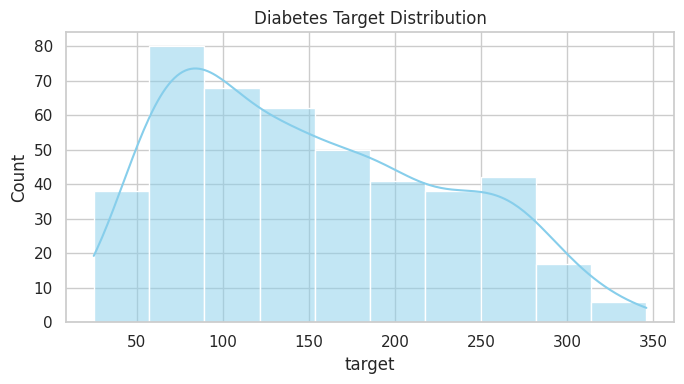

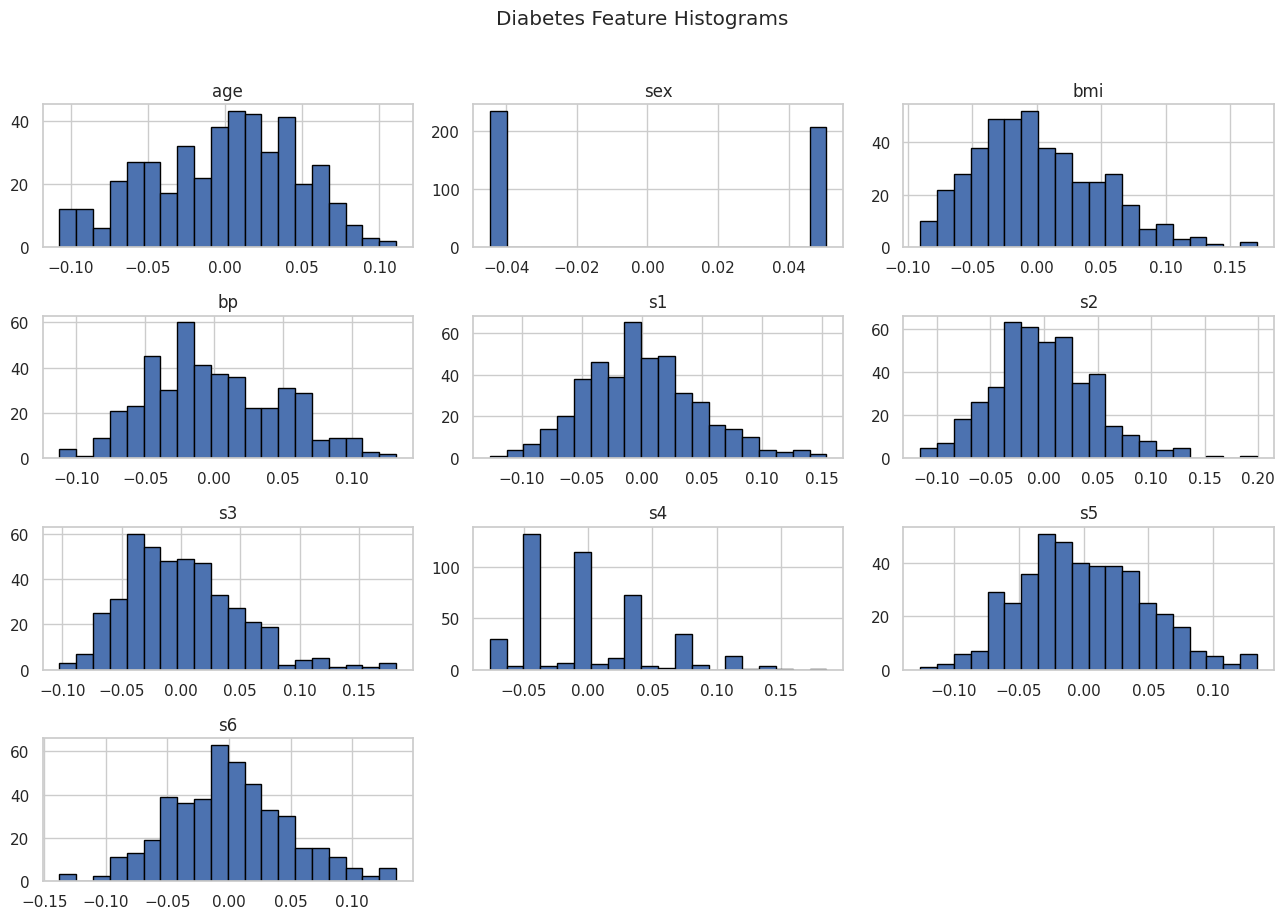

In [17]:
# Target distribution and feature histograms
plt.figure(figsize=(7, 4))
sns.histplot(data=df_reg, x="target", kde=True, color="skyblue")
plt.title("Diabetes Target Distribution")
plt.tight_layout()
plt.show()

df_reg.drop(columns=["target"]).hist(figsize=(13, 9), bins=20, edgecolor="black")
plt.suptitle("Diabetes Feature Histograms", y=1.02)
plt.tight_layout()
plt.show()

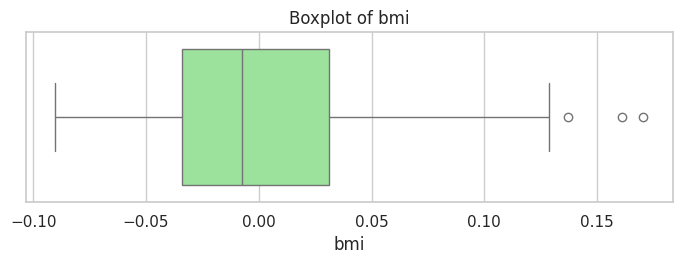

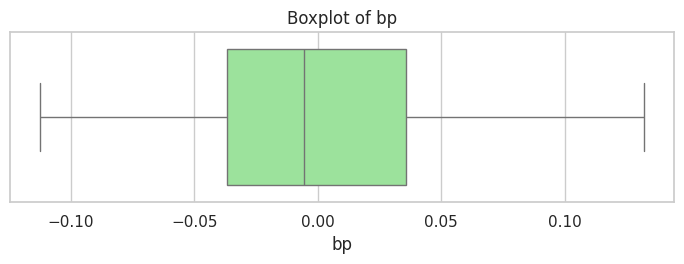

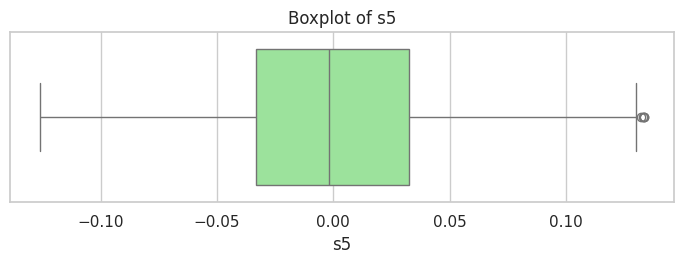

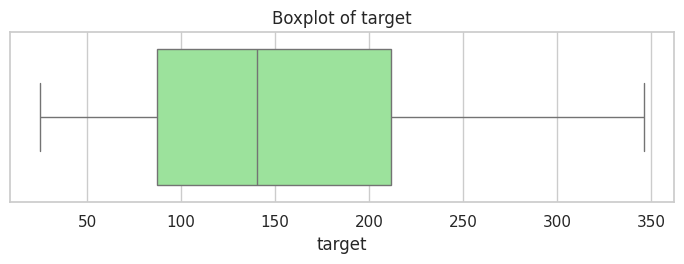

In [18]:
# Boxplots to inspect feature and target distributions
for col in ["bmi", "bp", "s5", "target"]:
    plt.figure(figsize=(7, 2.8))
    sns.boxplot(x=df_reg[col], color="lightgreen")
    plt.title(f"Boxplot of {col}")
    plt.tight_layout()
    plt.show()

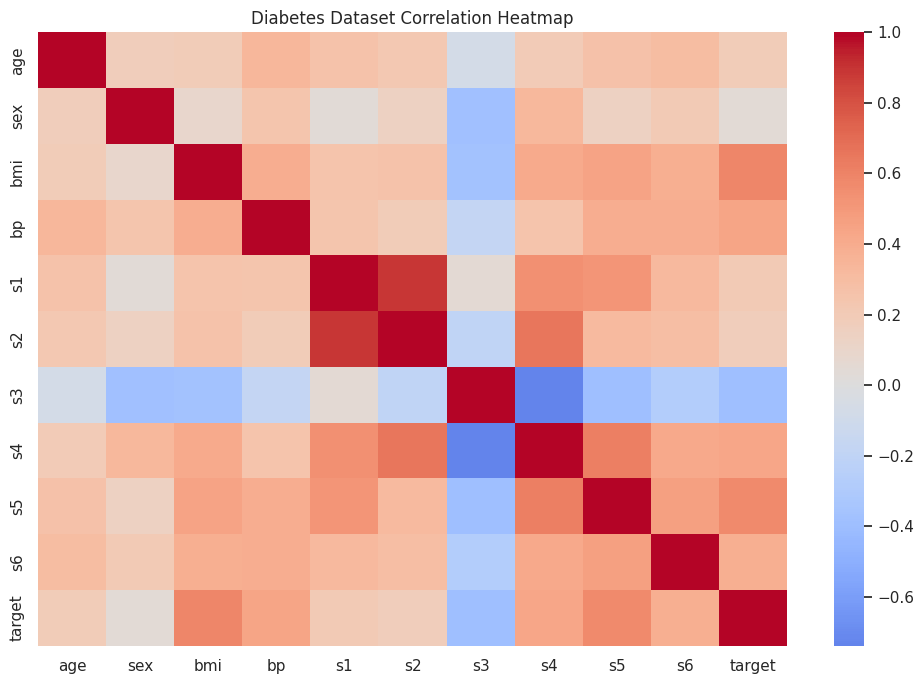

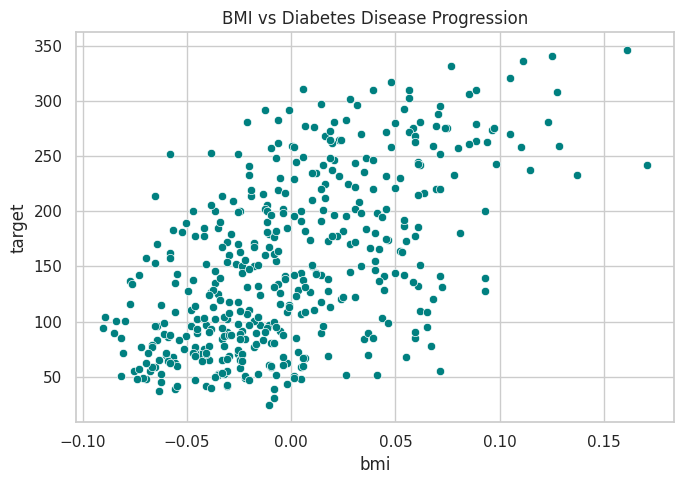

In [19]:
# Correlation heatmap and a feature-target scatter plot
plt.figure(figsize=(10, 7))
sns.heatmap(df_reg.corr(), cmap="coolwarm", center=0, annot=False)
plt.title("Diabetes Dataset Correlation Heatmap")
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 5))
sns.scatterplot(data=df_reg, x="bmi", y="target", color="teal")
plt.title("BMI vs Diabetes Disease Progression")
plt.tight_layout()
plt.show()

### Train and Evaluate KNN Regressor

In [20]:
X_reg = df_reg.drop(columns=["target"])
y_reg = df_reg["target"]

X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(
    X_reg, y_reg, test_size=0.2, random_state=42
)

print("Training features:", X_train_r.shape)
print("Testing features:", X_test_r.shape)

Training features: (353, 10)
Testing features: (89, 10)


In [21]:
knn_regressor = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsRegressor(n_neighbors=5))
])

knn_regressor.fit(X_train_r, y_train_r)
y_pred_r = knn_regressor.predict(X_test_r)

In [22]:
mse = mean_squared_error(y_test_r, y_pred_r)
rmse = np.sqrt(mse)

print("Mean Absolute Error (MAE):", round(mean_absolute_error(y_test_r, y_pred_r), 4))
print("Mean Squared Error (MSE):", round(mse, 4))
print("Root Mean Squared Error (RMSE):", round(rmse, 4))
print("R-squared (R²):", round(r2_score(y_test_r, y_pred_r), 4))

Mean Absolute Error (MAE): 42.7775
Mean Squared Error (MSE): 3047.4499
Root Mean Squared Error (RMSE): 55.2037
R-squared (R²): 0.4248


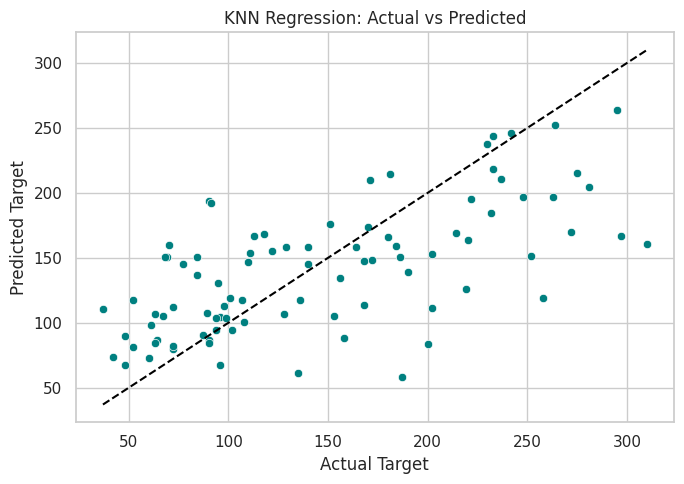

In [23]:
# Actual versus predicted target values
plt.figure(figsize=(7, 5))
sns.scatterplot(x=y_test_r, y=y_pred_r, color="teal")
min_val = min(y_test_r.min(), y_pred_r.min())
max_val = max(y_test_r.max(), y_pred_r.max())
plt.plot([min_val, max_val], [min_val, max_val], linestyle="--", color="black")
plt.xlabel("Actual Target")
plt.ylabel("Predicted Target")
plt.title("KNN Regression: Actual vs Predicted")
plt.tight_layout()
plt.show()

In [24]:
# Compare actual and predicted values
regression_comparison = pd.DataFrame({
    "Actual Target": y_test_r.reset_index(drop=True),
    "Predicted Target": np.round(y_pred_r, 2)
})
display(regression_comparison.head(10))

,Actual Target,Predicted Target
0,219.0,125.6
1,70.0,160.2
2,202.0,153.0
3,230.0,238.0
4,111.0,153.4
5,84.0,150.4
6,242.0,246.2
7,272.0,170.0
8,94.0,94.4
9,96.0,104.6


## Viva Questions with Answers

**1. What is KNN?**

K-Nearest Neighbors is a supervised learning algorithm that predicts a sample's class or numeric value based on its nearest training examples.

**2. Why is feature scaling important in KNN?**

KNN uses distance calculations. Scaling prevents features with larger numeric ranges from dominating the distance.

**3. How does KNN classification differ from KNN regression?**

Classification selects the most common class among the nearest neighbors, while regression generally averages their target values.

**4. What happens if the value of K is too small or too large?**

A very small K can overfit noise; a very large K may underfit by smoothing over local patterns.

**5. Name two distance metrics used in KNN.**

Euclidean distance and Manhattan distance are common distance metrics.

## Conclusion
The KNN algorithm was implemented for both classification and regression. EDA was performed before model training to inspect the datasets, distributions, outliers, and feature relationships. Classification performance was evaluated using accuracy, precision, recall, F1-score, and a confusion matrix, while regression performance was evaluated using MAE, MSE, RMSE, and R².